# Figure 1 — ExPert learns cross-context perturbation prototypes for inverse inference

Renders panels A, D and E from the cached tables in `data/` (written by `fig1b_data.py`, `fig1d_data.py`, `fig1d_tree.py`). Panels go to `render/`; the side tables the plot functions emit (`fig1c_col_order.json`, `fig1d_cluster_labels.csv`) go to `render/src/`.

Panels **B** (model overview) and **C** (forward vs inverse problems) are hand-drawn schematics: no script draws them, so they are not rendered here.

In [1]:
import sys
from pathlib import Path
_paper = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'scripts' / 'common').is_dir())
sys.path.insert(0, str(_paper / 'scripts' / 'common'))
import nbtools as nb                      # puts paper/scripts/*/ on sys.path

vs = nb.vizstyle()
DATA, INPUTS, OUT, SRC = nb.folders()     # data/ (cache), inputs/, render/, render/src/

In [2]:
import json
import pandas as pd
import fig1b_plot as C          # panel A (file name keeps the old 'fig1c' prefix)
import fig1d_plot as D          # panels D and E

C.style(vs)

## A — training corpus: per-context cells, perturbation x context matrix, breadth marginal, dataset/system rings

[colour] cells per perturbation x context: scale 10 .. 1,290 (99th percentile, saturates above); max 10,072


column order: TeloHAEC, HCT116, HEK293T, Rest, 8 h, 48 h, K562, KOLF2.1J, hESC, HepG2, Jurkat, RPE1


<env>/lib/python3.11/site-packages/anndata/utils.py:429: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
<env>/lib/python3.11/site-packages/anndata/utils.py:429: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
<env>/lib/python3.11/site-packages/anndata/utils.py:429: FutureWarning: Importing read_hdf from `anndata` is deprecated. Import anndata.io.read_hdf instead.
  warnings.warn(msg, FutureWarning)
<env>/lib/python3.11/site-packages/anndata/utils.py:429: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  warnings.warn(msg, FutureWarning)
<env>/lib/python3.11/site-packages/anndata/utils.py:429: FutureWarning: Importing read_mtx from `anndata` is deprecated. Import anndata.io.read_mtx instead.
  warnings.warn(msg, FutureWarning)
<env>/lib/python3.11/site-pac

          ctx  sel_in_db  unsel_measured
col                                     
0    TeloHAEC      0.122           0.048
1      HCT116      0.854           0.897
2     HEK293T      0.908           0.911
3        Rest      0.835           0.366
4         8 h      0.839           0.367
5        48 h      0.835           0.366
6        K562      0.944           0.087
7    KOLF2.1J      0.822           0.354
8        hESC      0.270           0.054
9       HepG2      0.099           0.006
10     Jurkat      0.179           0.006
11       RPE1      0.150           0.006


  wrote fig1c_training_corpus.svg / .png


rows 19,191 (selected 8,964); contexts 12 (9 counted)


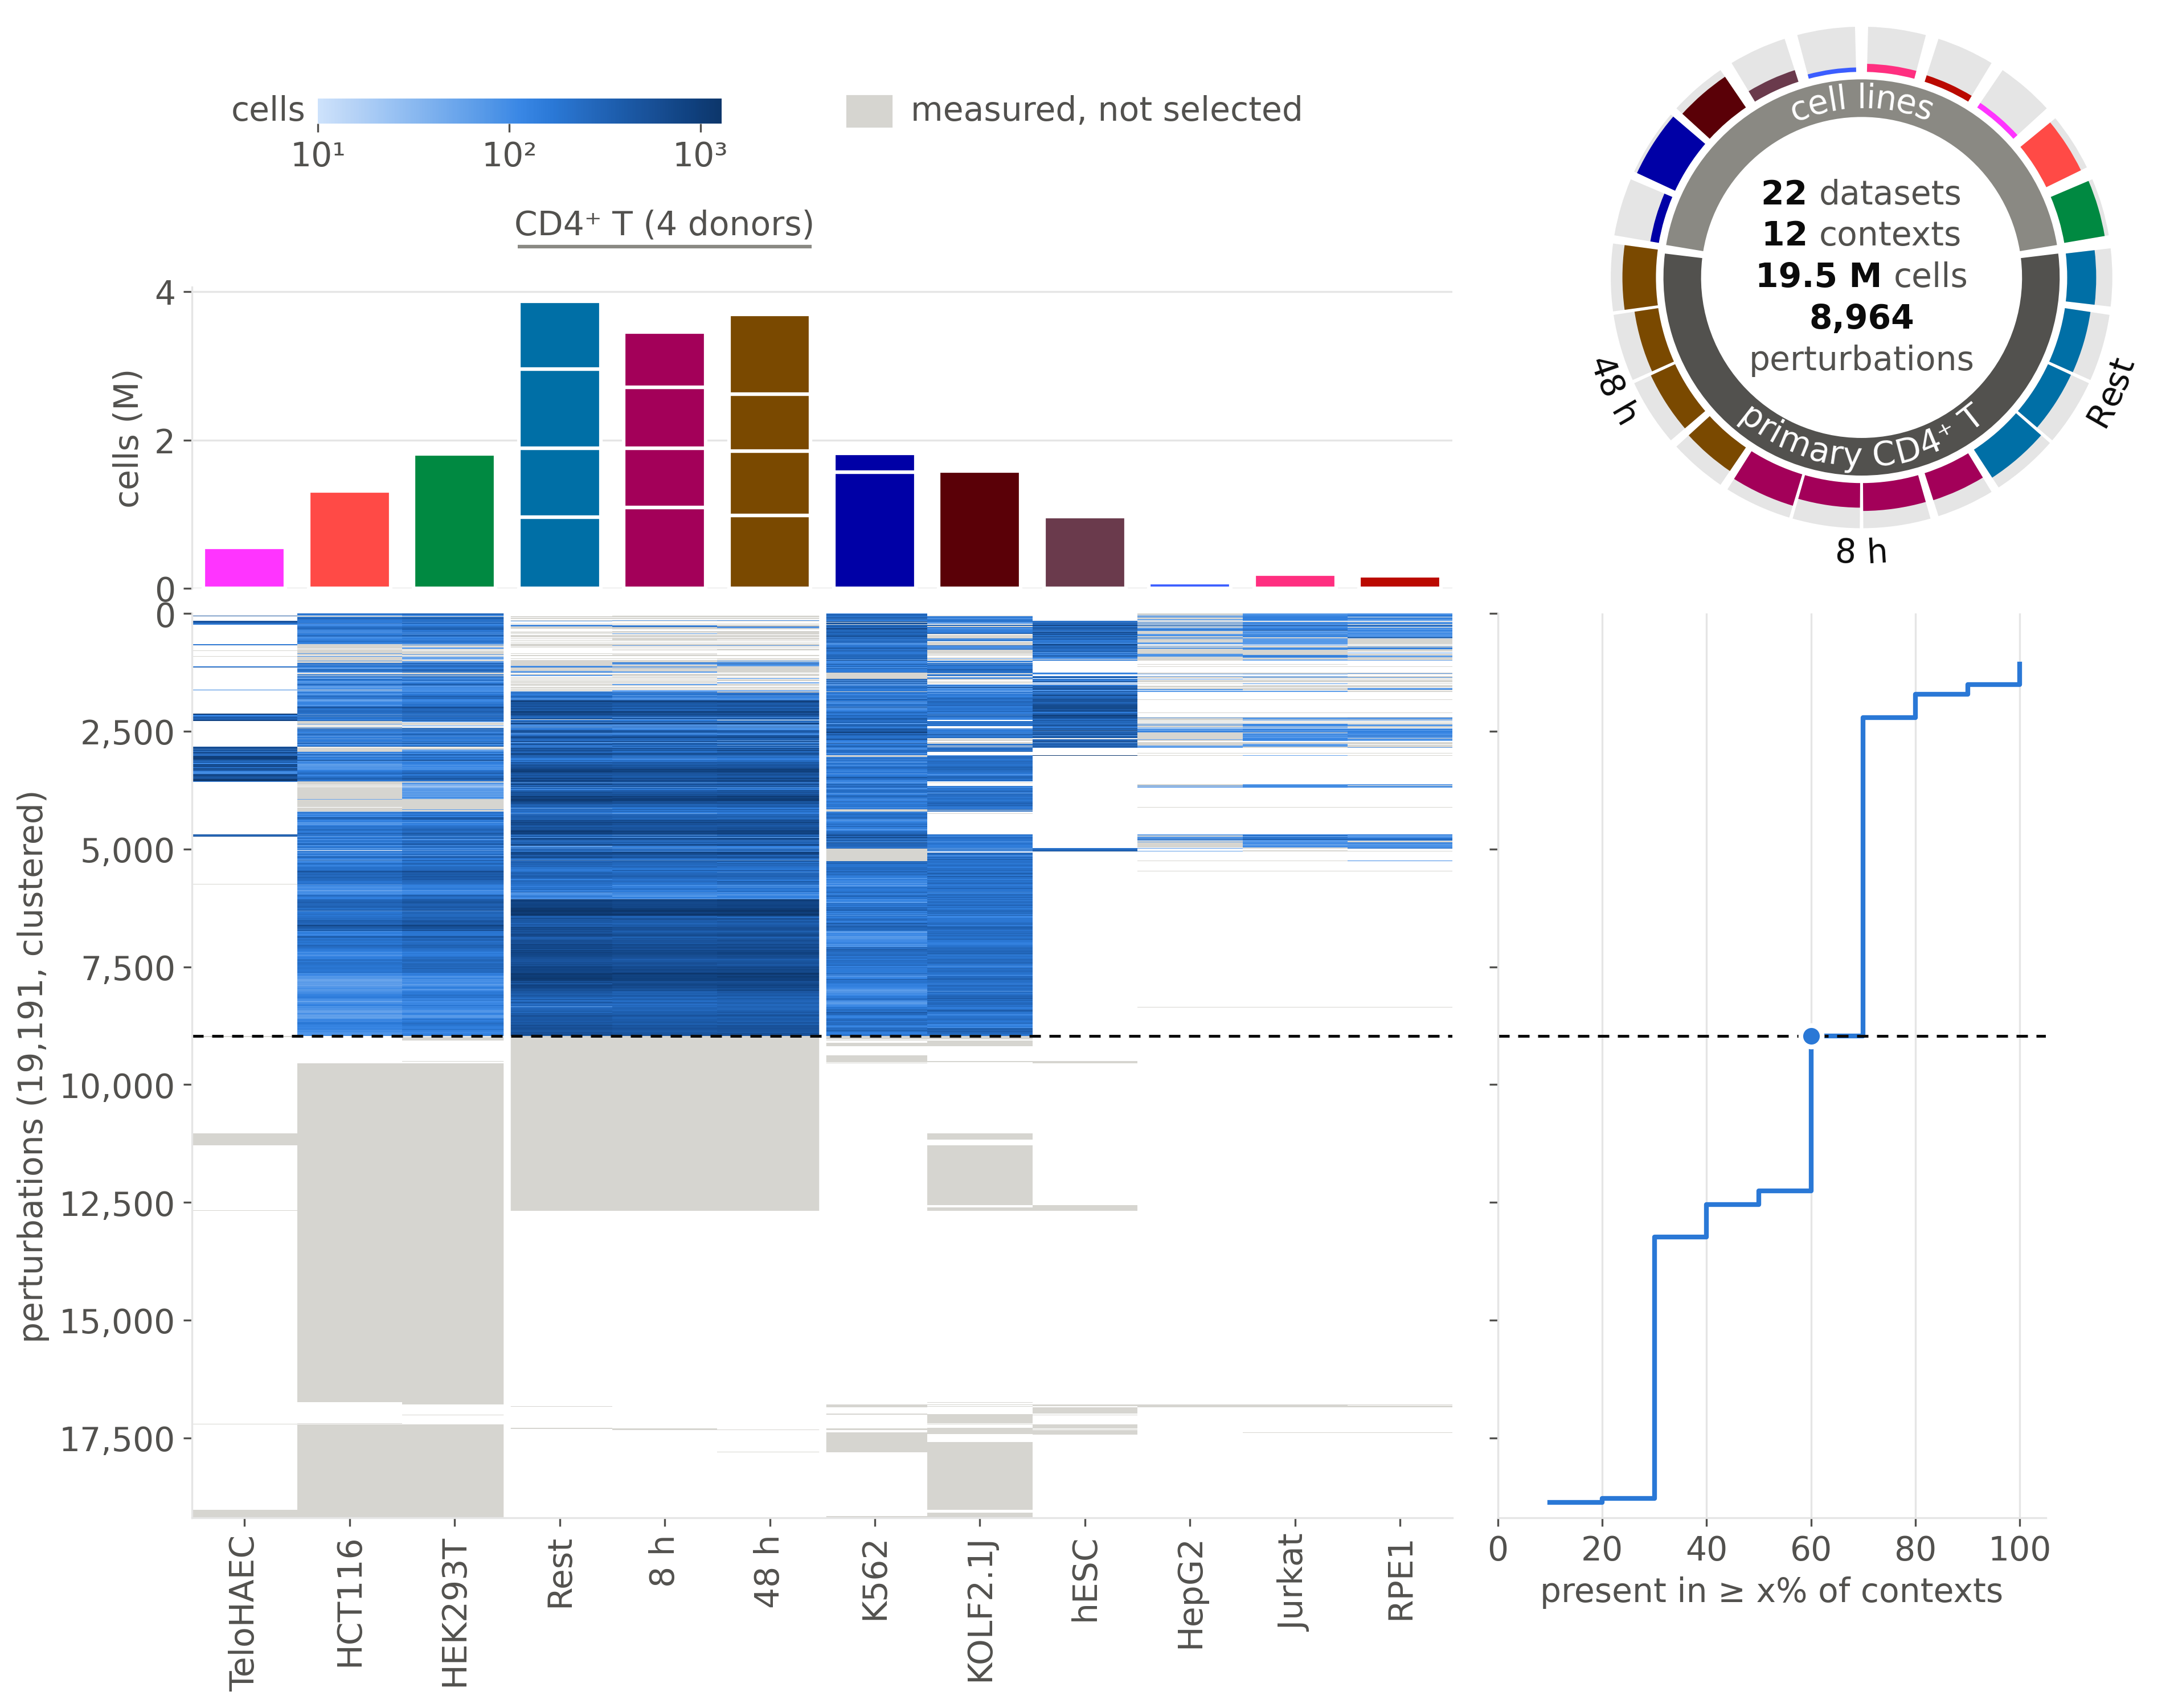

In [3]:
C.plot(DATA, OUT, vs, name='fig1c_training_corpus', col_order='cluster', row_order='cluster', col_order_out=SRC)
nb.show(OUT, 'fig1c_training_corpus')

## B, C — schematics (hand-drawn; not rendered)

## D — cosine UMAP of the 8,964 prototypes, coloured by specifically enriched Leiden cluster

  wrote fig1d_prototype_umap.svg / .png


[1d] 44 coloured + labelled clusters; grey 5,370


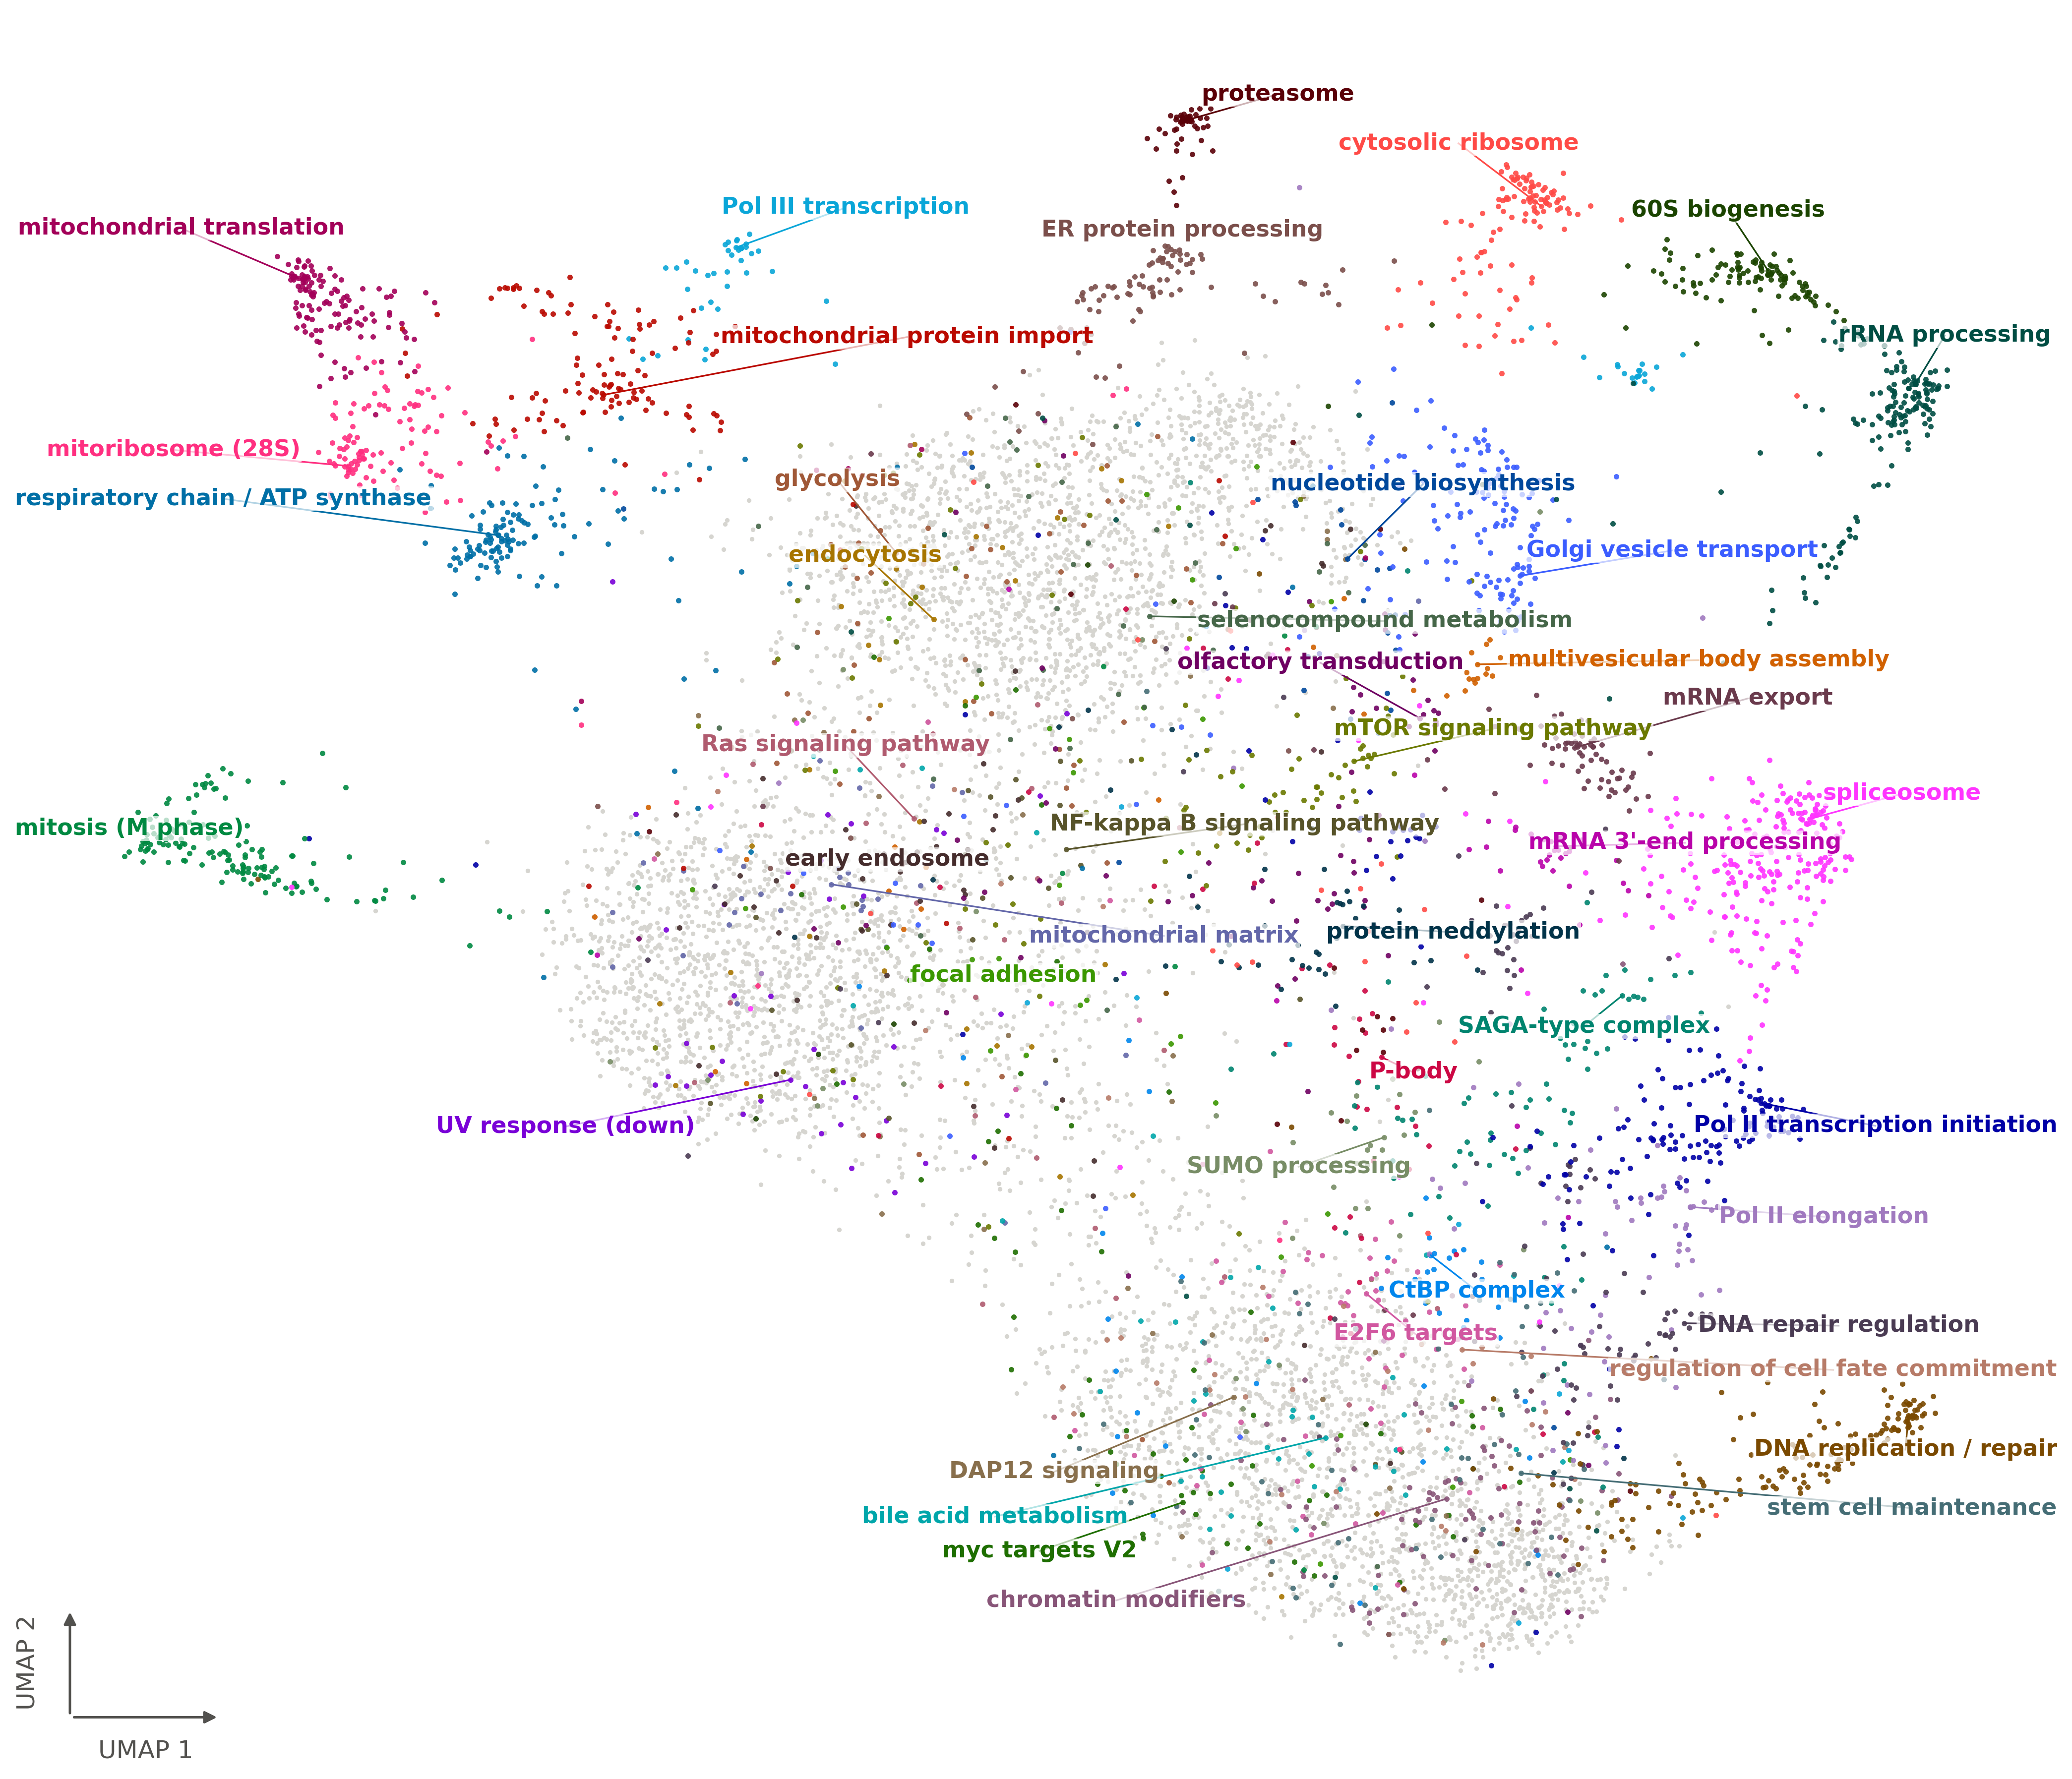

In [4]:
D.style(vs)
lay = pd.read_parquet(DATA / 'fig1d_layout.parquet')
D.umap_panel(DATA, lay, 'leiden_4', vs, OUT, 'fig1d_prototype_umap', src_dir=SRC)
nb.show(OUT, 'fig1d_prototype_umap')

## E — agreement between prototype geometry and external gene priors

  wrote fig1e_prior_agreement.svg / .png


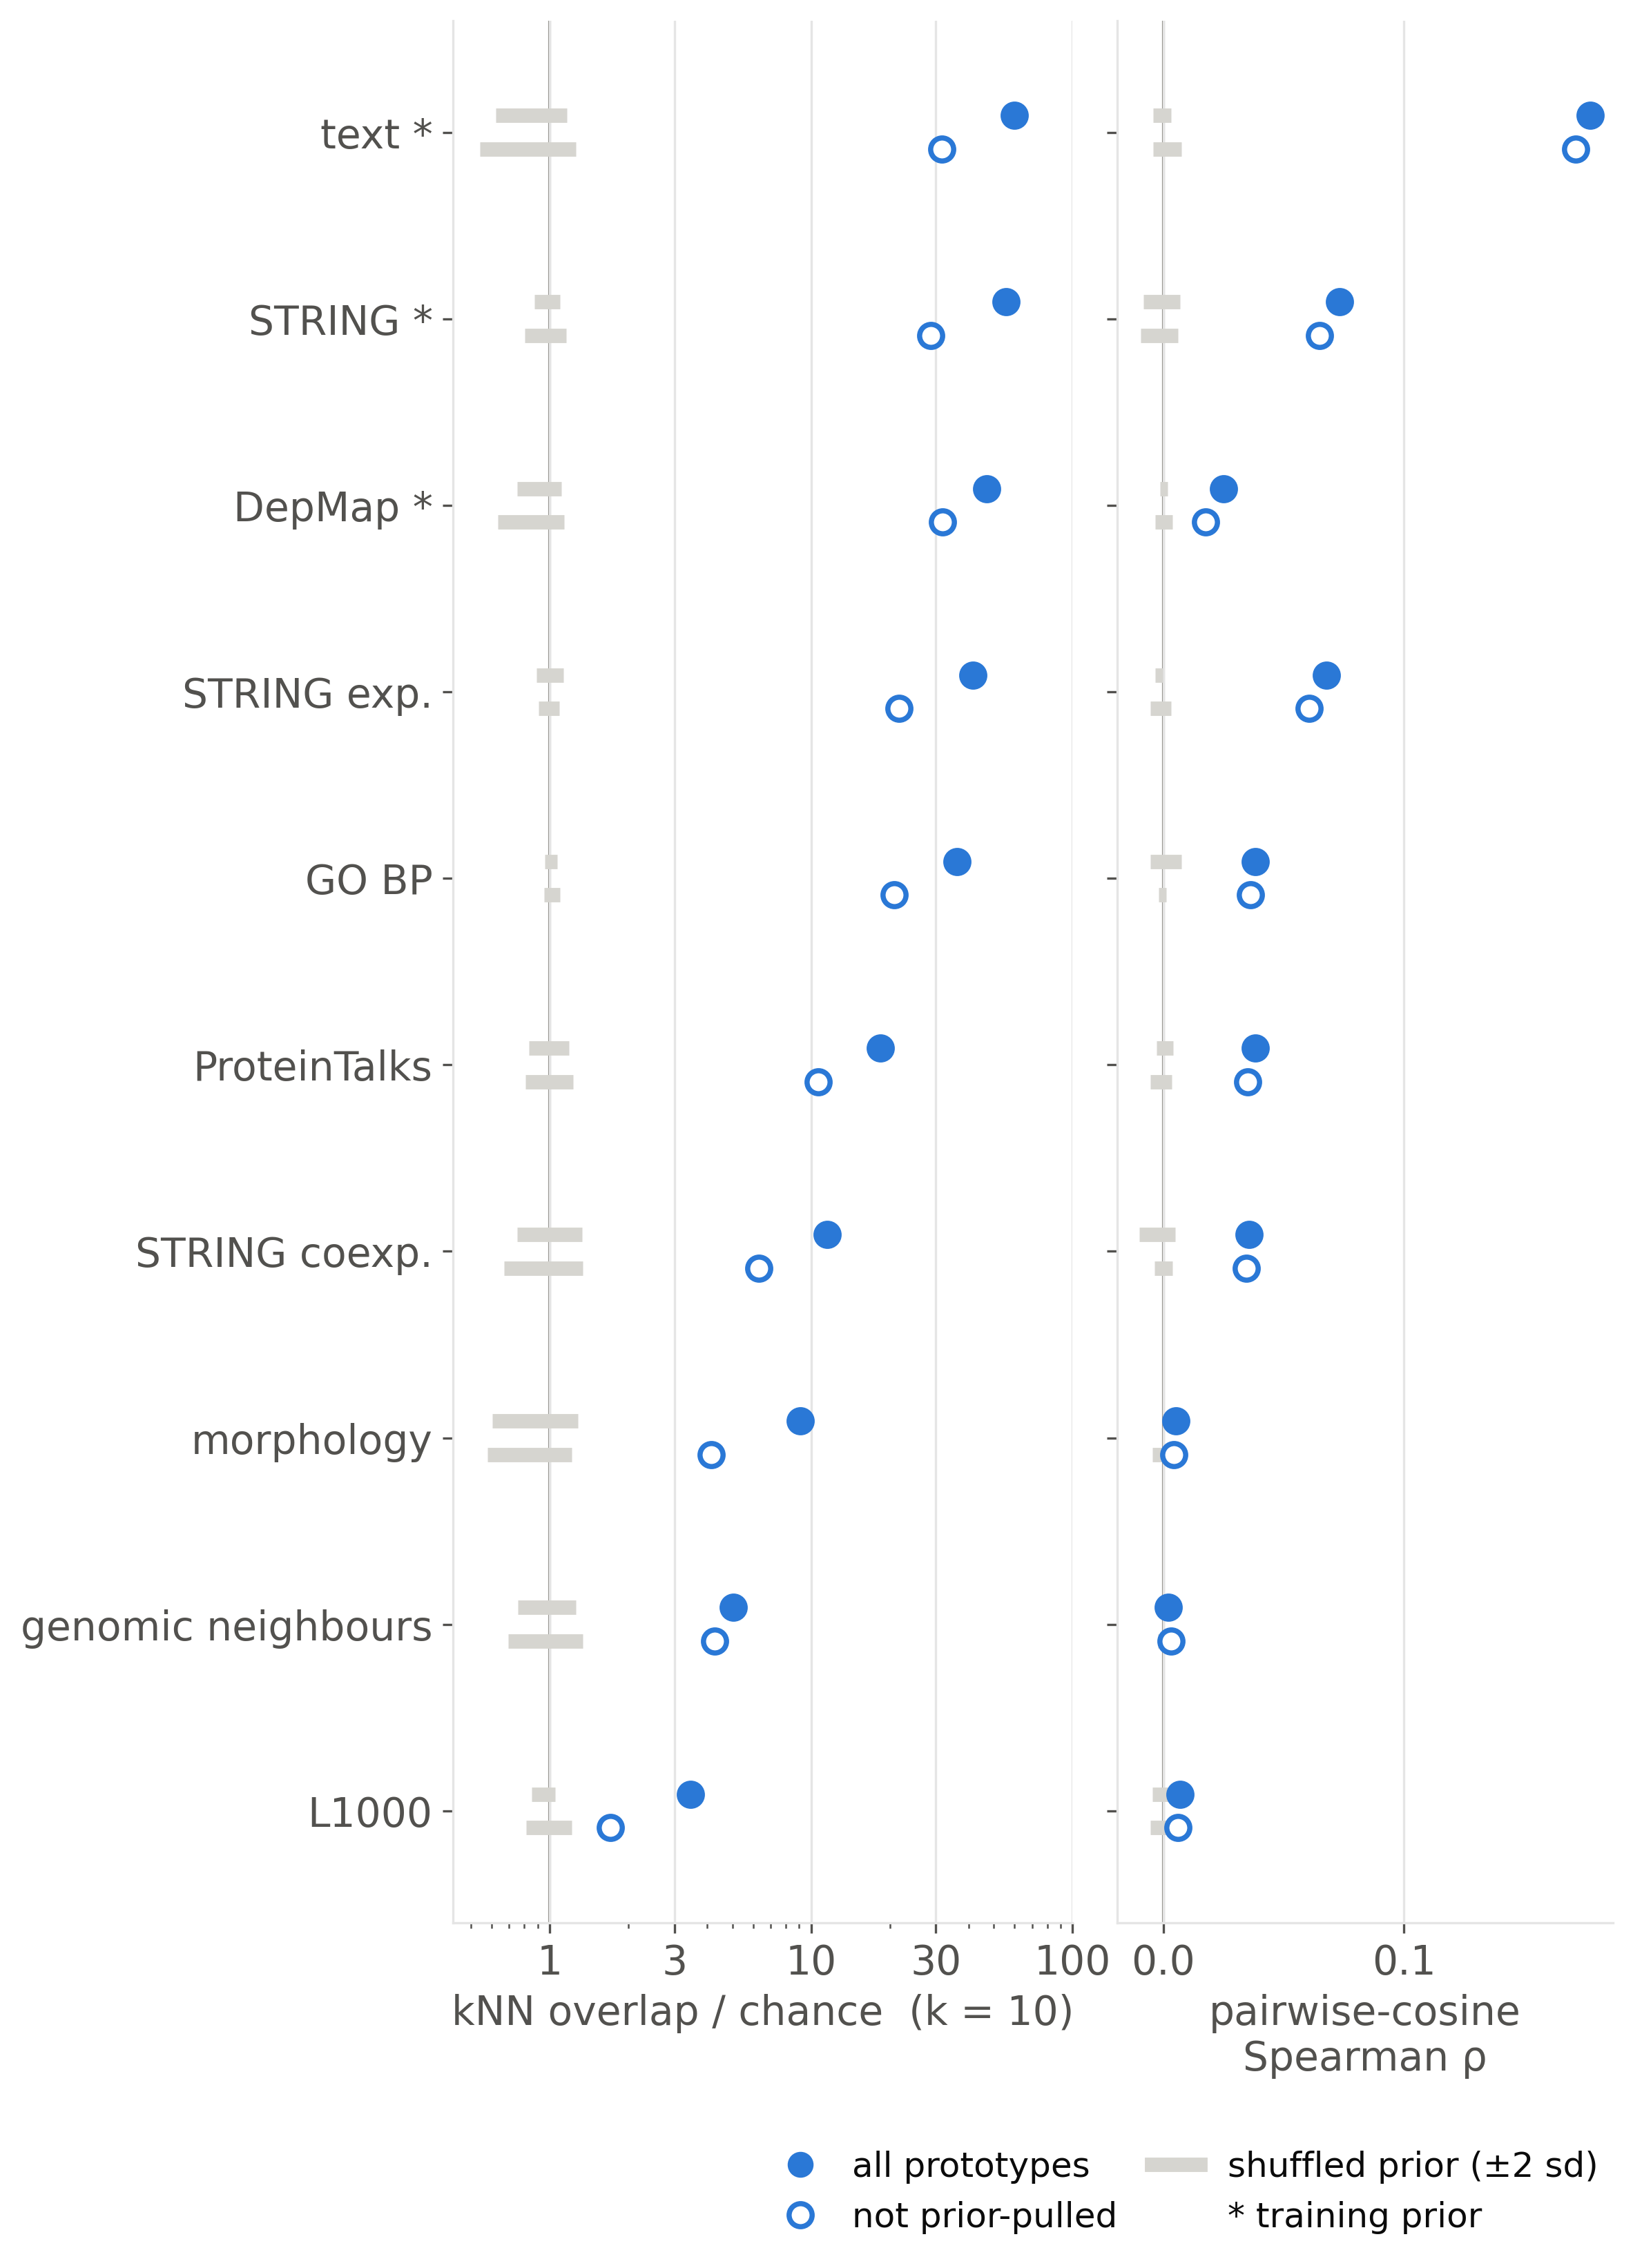

In [5]:
agr = pd.read_csv(DATA / 'fig1e_agreement.csv')
meta = json.loads((DATA / 'fig1e_meta.json').read_text())
D.agreement_panel(agr, meta, vs, OUT, 'fig1e_prior_agreement')
nb.show(OUT, 'fig1e_prior_agreement')